Este código muestra las activaciones intermedias de cada capa para una imagen de entrada, permitiéndote observar cómo "ve" la red en cada etapa.

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Cargar datos
(x_train, y_train), (_, _) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
x_train = x_train / 255.0

In [5]:
# Elegir imagen de entrada
img_idx = 0
img = x_train[img_idx].reshape(1, 28, 28)

In [6]:
# Construir modelo
inputs = tf.keras.Input(shape=(28, 28))
x = Flatten()(inputs)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = Dense(32, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)

In [7]:
model = Model(inputs, outputs)

In [8]:
# Crear modelo intermedio para obtener activaciones
layer_outputs = [layer.output for layer in model.layers if 'dense' in layer.name]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

In [9]:
# Obtener activaciones
activations = activation_model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


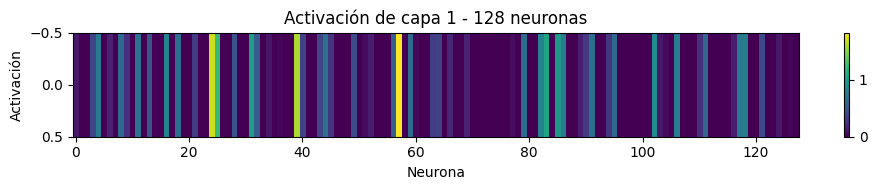

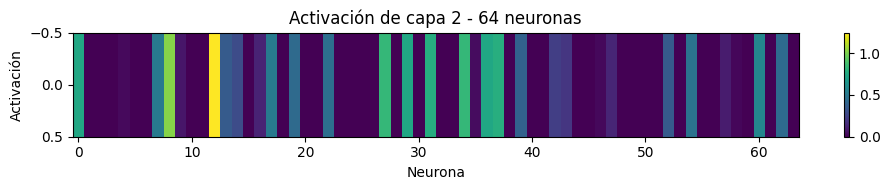

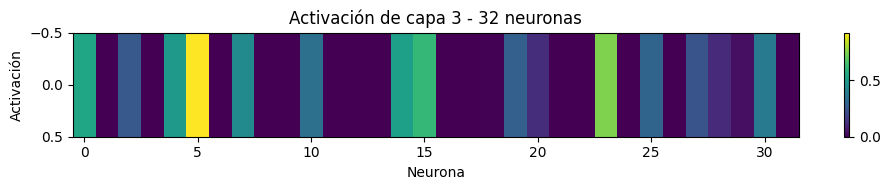

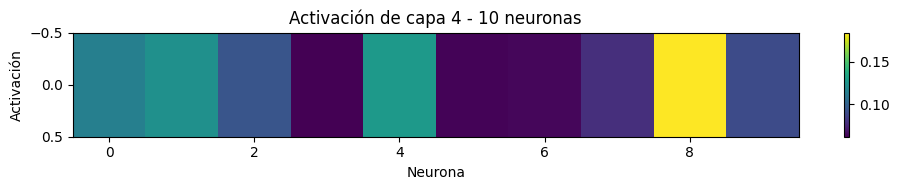

In [10]:
# Visualizar
for layer_num, activation in enumerate(activations):
    plt.figure(figsize=(10, 2))
    plt.title(f'Activación de capa {layer_num+1} - {activation.shape[-1]} neuronas')
    plt.imshow(activation, aspect='auto', cmap='viridis')
    plt.xlabel("Neurona")
    plt.ylabel("Activación")
    plt.colorbar()
    plt.tight_layout()
    plt.show()